In [1]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving archive (4).zip to archive (4).zip
Uploaded files: ['archive (4).zip']


In [2]:

import os
import glob
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_folder = "/content/employee_attrition_data"
os.makedirs(data_folder, exist_ok=True)

for filename in uploaded.keys():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as z:
            z.extractall(data_folder)
    elif filename.lower().endswith(".csv"):
        destination = os.path.join(data_folder, filename)
        with open(filename, "rb") as source:
            with open(destination, "wb") as target:
                target.write(source.read())

csv_files = glob.glob(
    os.path.join(data_folder, "**", "*.csv"),
    recursive=True
)

print("CSV files found:")
for path in csv_files:
    print(path)

if not csv_files:
    raise FileNotFoundError(
        "No CSV found. Upload the dataset CSV or ZIP file."
    )

# Prefer the standard IBM attrition dataset when present
matching_files = [
    path for path in csv_files
    if "attrition" in os.path.basename(path).lower()
]
csv_path = matching_files[0] if matching_files else csv_files[0]

df = pd.read_csv(csv_path)

print("\nDataset loaded successfully")
print("Shape:", df.shape)
display(df.head())


CSV files found:
/content/employee_attrition_data/WA_Fn-UseC_-HR-Employee-Attrition.csv

Dataset loaded successfully
Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nAttrition counts:")
if "Attrition" in df.columns:
    display(df["Attrition"].value_counts())
else:
    raise ValueError(
        "The dataset has no 'Attrition' column. "
        "Check which CSV was loaded."
    )

print("\nNumeric summary:")
display(df.describe().T)


Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel   

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0



Attrition counts:


,count
Attrition,
No,1233
Yes,237



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


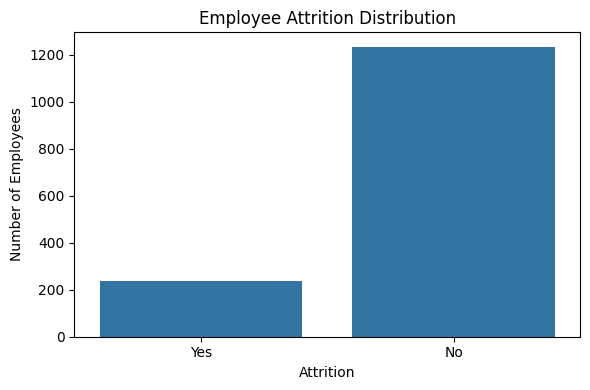

Overall attrition rate: 16.12 %


In [4]:

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

print(
    "Overall attrition rate:",
    round((df["Attrition"] == "Yes").mean() * 100, 2),
    "%"
)


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Remove columns that don't provide useful predictive information
drop_columns = [
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

df_model = df.drop(columns=drop_columns, errors="ignore").copy()

# Convert target to binary: Yes = 1, No = 0
y = df_model["Attrition"].map({"Yes": 1, "No": 0})

if y.isnull().any():
    raise ValueError(
        "Unexpected values in Attrition. Check df['Attrition'].unique()."
    )

X = df_model.drop(columns=["Attrition"])

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Training rows: 1176
Testing rows: 294
Numeric features: 23
Categorical features: 7


In [6]:
preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=0
)

In [7]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42
    ),
    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=500, early_stopping=True, random_state=42
    ),
    "Gaussian Naive Bayes": GaussianNB(),
    "Linear Discriminant Analysis": LinearDiscriminantAnalysis()
}

results = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    try:
        pipeline.fit(X_train, y_train)

        predictions = pipeline.predict(X_test)

        if hasattr(pipeline, "predict_proba"):
            probabilities = pipeline.predict_proba(X_test)[:, 1]
        else:
            probabilities = pipeline.decision_function(X_test)

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_test, probabilities)
        })

        trained_models[name] = pipeline

    except Exception as error:
        print("Model failed:", name, error)

results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Neural Network
Training: Gaussian Naive Bayes
Training: Linear Discriminant Analysis


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7517,0.3488,0.6383,0.4511,0.8032
1,Linear Discriminant Analysis,0.8639,0.6207,0.3830,0.4737,0.7971
2,Neural Network,0.8605,0.6250,0.3191,0.4225,0.7915
3,Random Forest,0.8469,0.6250,0.1064,0.1818,0.7832
4,Gaussian Naive Bayes,0.6463,0.2605,0.6596,0.3735,0.7032
5,Decision Tree,0.7551,0.2642,0.2979,0.2800,0.5700


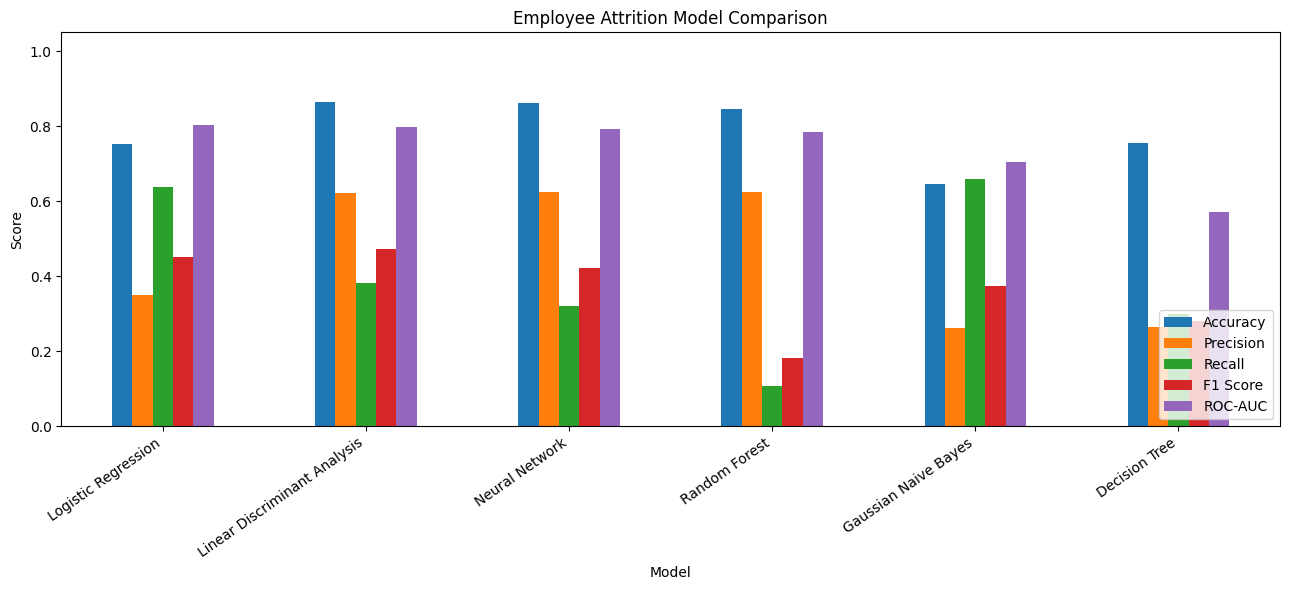

In [8]:

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Employee Attrition Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Top model by ROC-AUC: Logistic Regression

Classification report:
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



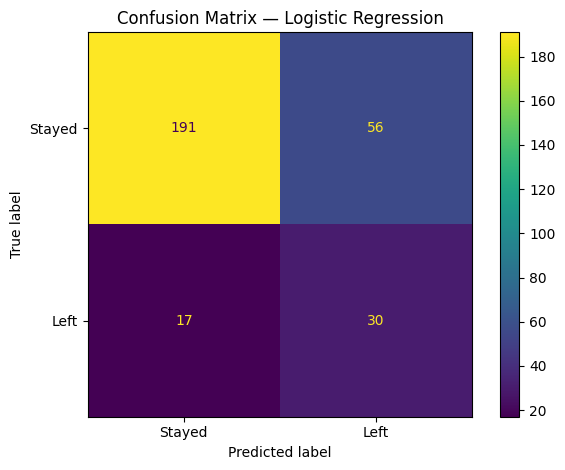

In [9]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Top model by ROC-AUC:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, best_predictions,
    target_names=["Stayed", "Left"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Stayed", "Left"]
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


Top model by ROC-AUC: Logistic Regression

Classification report:
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



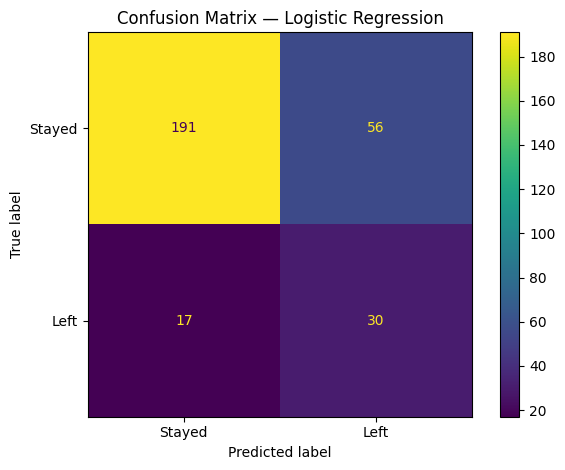

In [10]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Top model by ROC-AUC:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, best_predictions,
    target_names=["Stayed", "Left"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Stayed", "Left"]
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


In [11]:

# Department-level attrition
department_summary = (
    df.groupby("Department")
      .agg(
          Total_Employees=("Attrition", "size"),
          Employees_Left=("Attrition", lambda s: (s == "Yes").sum())
      )
      .reset_index()
)

department_summary["Attrition_Rate_Percent"] = (
    department_summary["Employees_Left"]
    / department_summary["Total_Employees"] * 100
).round(2)

display(department_summary)

# Workforce demographics
if "Age" in df.columns:
    print("Average employee age:", round(df["Age"].mean(), 2))

if "Gender" in df.columns:
    display(pd.crosstab(df["Gender"], df["Attrition"]))

# Overall HR KPIs
total_employees = len(df)
employees_left = (df["Attrition"] == "Yes").sum()
employees_stayed = total_employees - employees_left

print("Total employees:", total_employees)
print("Employees who left:", employees_left)
print("Employees who stayed:", employees_stayed)
print("Attrition rate:", round(100 * employees_left / total_employees, 2), "%")
print("Retention rate:", round(100 * employees_stayed / total_employees, 2), "%")


,Department,Total_Employees,Employees_Left,Attrition_Rate_Percent
0,Human Resources,63,12,19.05
1,Research & Development,961,133,13.84
2,Sales,446,92,20.63


Average employee age: 36.92


Attrition,No,Yes
Gender,,
Female,501,87
Male,732,150


Total employees: 1470
Employees who left: 237
Employees who stayed: 1233
Attrition rate: 16.12 %
Retention rate: 83.88 %


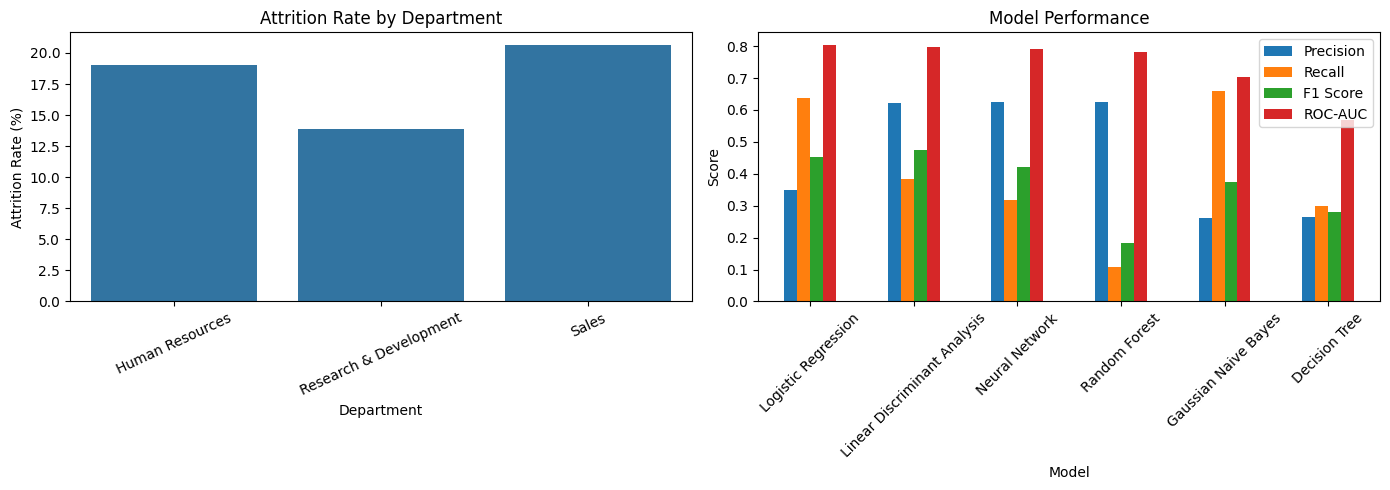

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=department_summary,
    x="Department",
    y="Attrition_Rate_Percent",
    ax=axes[0]
)
axes[0].set_title("Attrition Rate by Department")
axes[0].set_ylabel("Attrition Rate (%)")
axes[0].tick_params(axis="x", rotation=25)

results_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", ax=axes[1])
axes[1].set_title("Model Performance")
axes[1].set_ylabel("Score")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("HR_Analytics_Dashboard.png", dpi=150, bbox_inches="tight")
plt.show()


In [13]:

risk_df = X_test.copy()
risk_df["Actual_Attrition"] = y_test.values

risk_df["Predicted_Attrition_Probability"] = (
    best_model.predict_proba(X_test)[:, 1]
)

risk_df["Risk_Category"] = pd.cut(
    risk_df["Predicted_Attrition_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)

display(
    risk_df[
        ["Predicted_Attrition_Probability", "Risk_Category",
         "Actual_Attrition"]
    ].head(10)
)

display(risk_df["Risk_Category"].value_counts().to_frame("Employee Count"))


,Predicted_Attrition_Probability,Risk_Category,Actual_Attrition
1061,0.286610,Low,0
891,0.021878,Low,0
456,0.407563,Medium,0
922,0.040382,Low,0
69,0.674098,High,1
1164,0.642287,High,0
406,0.080839,Low,0
1330,0.150257,Low,0
1232,0.020520,Low,0
1311,0.237788,Low,0


,Employee Count
Risk_Category,
Low,160
Medium,72
High,62


In [14]:

import joblib
import os

os.makedirs("employee_attrition_outputs", exist_ok=True)

joblib.dump(
    best_model,
    "employee_attrition_outputs/best_attrition_model.joblib"
)

results_df.to_csv(
    "employee_attrition_outputs/model_comparison.csv",
    index=False
)

department_summary.to_csv(
    "employee_attrition_outputs/department_attrition.csv",
    index=False
)

risk_df.to_csv(
    "employee_attrition_outputs/employee_risk_predictions.csv",
    index=True
)

print("Saved model and CSV reports.")


Saved model and CSV reports.


In [15]:

import shutil
from google.colab import files

shutil.make_archive(
    "employee_attrition_outputs",
    "zip",
    "employee_attrition_outputs"
)

files.download("employee_attrition_outputs.zip")
files.download("HR_Analytics_Dashboard.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>